In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from optical_communication_system.components import *
from optical_communication_system.components.utils import normalize_signal

2024-08-23 17:31:03.547569: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-08-23 17:31:03.584873: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-08-23 17:31:03.584900: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-08-23 17:31:03.586053: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-08-23 17:31:03.591990: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-08-23 17:31:03.592453: I tensorflow/core/platform/cpu_feature_guard.cc:1

Text(0, 0.5, 'Bit value')

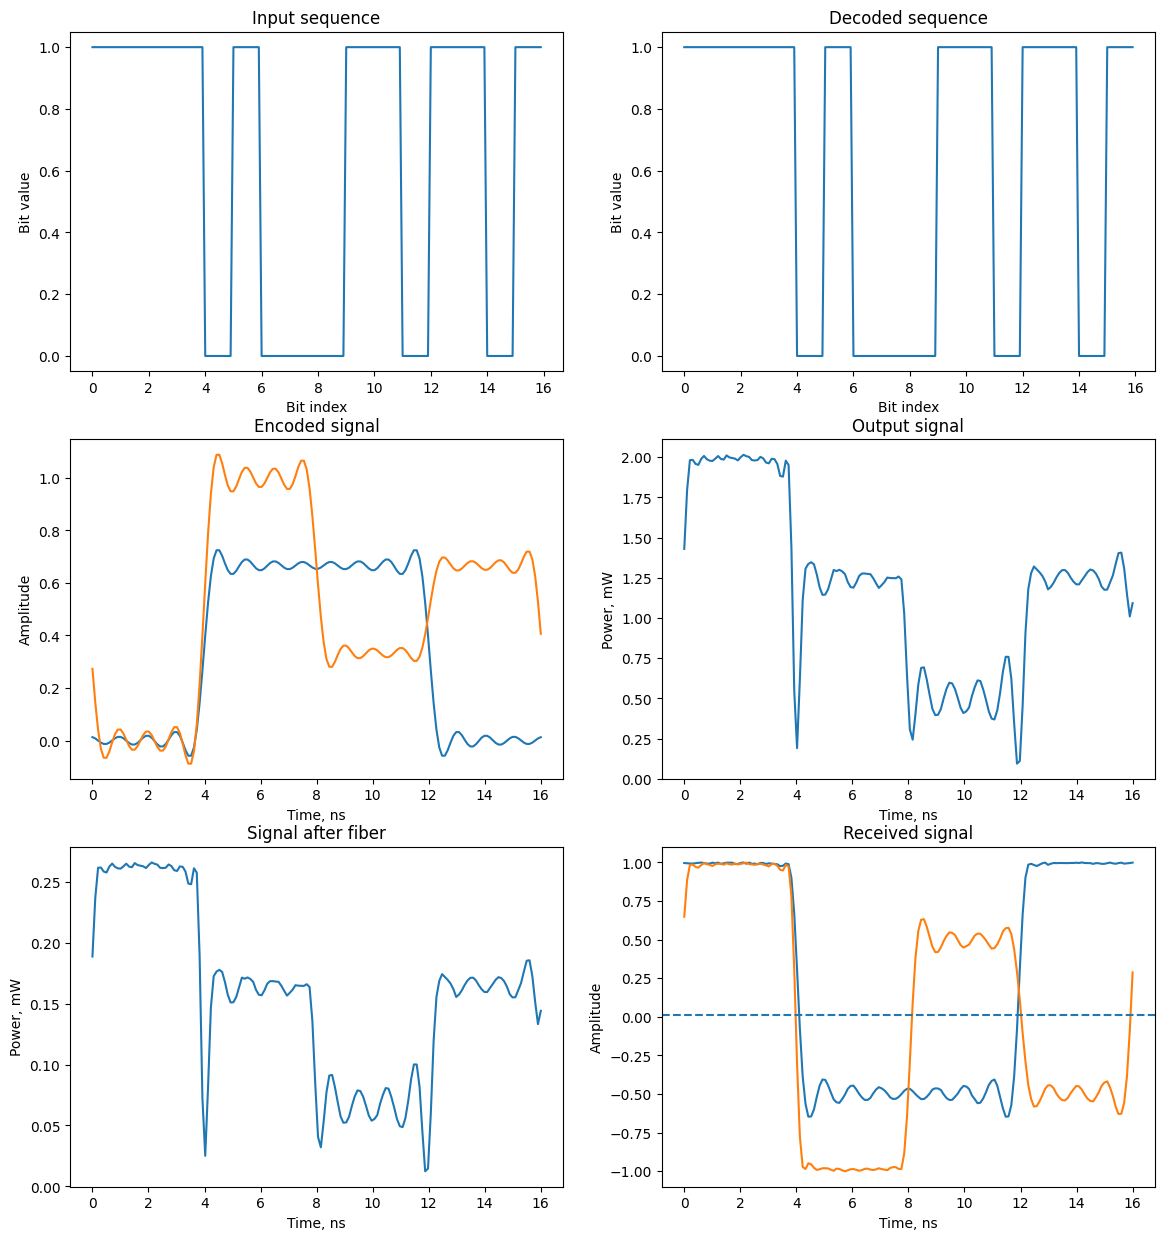

In [2]:
pam_order = 1
data_rate = 1e9
sampling_rate = data_rate * 10

lpf = ElectricalLowPassFilter(cutoff_frequency=1 * data_rate)

qam4_constellation = QAMConstellation(
    order=2,
    mapping=[
        [-1.0, -1.0], [-1.0, 1.0],
        [ 1.0, -1.0], [ 1.0, 1.0]
    ],
    adjust_for_mzm=True
)

qam16_constellation = QAMConstellation(
    order=4,
    mapping=[
        [-1.0, -1.0], [-1.0, -0.5], [-1.0, 0.5], [-1.0, 1.0],
        [-0.5, -1.0], [-0.5, -0.5], [-0.5, 0.5], [-0.5, 1.0],
        [ 0.5, -1.0], [ 0.5, -0.5], [ 0.5, 0.5], [ 0.5, 1.0],
        [ 1.0, -1.0], [ 1.0, -0.5], [ 1.0, 0.5], [ 1.0, 1.0]
    ],
    adjust_for_mzm=True
)

encoder = System(components=[
    QAMEncoder(
        sampling_rate=sampling_rate,
        data_rate=data_rate,
        constellation=qam16_constellation
    ),
    MapComponent(component=lpf),
])

qam_transmitter = System(components=[
    QAMModulator(
        carrier_source=Transmitter(power=2e-3, linewidth=1e3, frequency_count=128)
    ),
    OpticalAWGN(level=-30.0)
])

transmitter = System(components=[
    PAMEncoder(sampling_rate=sampling_rate, data_rate=data_rate, order=pam_order),
    lpf,
    MachZehnderModulator(
        carrier_source=Transmitter(power=2e-3, linewidth=10e9, frequency_count=128)
    ),
    OpticalAWGN(level=-30.0)
])

channel = OpticalFiber(attenuation=0.22, length=40.0, chromatic_dispersion=0.0)
receiver = System(components=[Photodiode(), lpf])
qam_receiver = QAMReceiver(
    photodiode=System(components=[Photodiode(), lpf])
)
decoder = PAMDecoder(data_rate=data_rate, order=pam_order)
qam_decoder = QAMDecoder(
    data_rate=data_rate,
    constellation=qam16_constellation
)

system = System(components=[encoder, qam_transmitter, channel, qam_receiver, qam_decoder])

input_signal = tf.constant([1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1], dtype=tf.int32)
encoded_signal = encoder(input_signal)
output_signal = qam_transmitter(encoded_signal)
fiber_signal = channel(output_signal)
received_signal = qam_receiver(fiber_signal)
decoded_signal = qam_decoder(received_signal)

fig, ((input_ax, decoded_ax), (encoded_ax, output_ax), (fiber_ax, received_ax)) = plt.subplots(3, 2)
fig.set_size_inches(14, 15)

input_ax.set_title("Input sequence")
encoded_ax.set_title("Encoded signal")
output_ax.set_title("Output signal")
fiber_ax.set_title("Signal after fiber")
received_ax.set_title("Received signal")
decoded_ax.set_title("Decoded sequence")

input_ax.plot(np.arange(0, input_signal.numpy().size, 0.1), input_signal.numpy().repeat(10))
input_ax.set_xlabel("Bit index")
input_ax.set_ylabel("Bit value")

for signal in encoded_signal:
    encoded_ax.plot(signal.timing.time * 1e9, signal.samples.numpy())

encoded_ax.set_xlabel("Time, ns")
encoded_ax.set_ylabel("Amplitude")

output_ax.plot(output_signal.timing.time * 1e9, np.sum(np.abs(output_signal.samples.numpy())**2 * 1000, axis=1))
output_ax.set_xlabel("Time, ns")
output_ax.set_ylabel("Power, mW")

fiber_ax.plot(fiber_signal.timing.time * 1e9, np.sum(np.abs(fiber_signal.samples.numpy())**2 * 1000, axis=1))
fiber_ax.set_xlabel("Time, ns")
fiber_ax.set_ylabel("Power, mW")

for signal in received_signal:
    received_ax.plot(signal.timing.time * 1e9, normalize_signal(signal.samples).numpy())

received_ax.axhline(decoder.threshold * 1000, linestyle="--")
received_ax.set_xlabel("Time, ns")
received_ax.set_ylabel("Amplitude")

decoded_ax.plot(np.arange(0, decoded_signal.numpy().size, 0.1), decoded_signal.numpy().repeat(10))
decoded_ax.set_xlabel("Bit index")
decoded_ax.set_ylabel("Bit value")

In [26]:
ber_tester = BERTester([system])

In [27]:
ber_tester(128, 100)

<tf.Tensor: shape=(1,), dtype=float32, numpy=array([0.], dtype=float32)>